<a href="https://colab.research.google.com/github/5josephine5/JosephineNg_DTSC3020_Fall2026/blob/main/DTSC3020_W10_Lesson8_(Copy).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<style>
.jp-RenderedHTMLCommon h1 { color: #0b6b3a; border-bottom: 2px solid #dcefe5; padding-bottom: 6px; }
.jp-RenderedHTMLCommon h2 { color: #0e5f43; margin-top: 28px; }
.jp-RenderedHTMLCommon h3 { color: #205b85; }
.callout { border-left: 7px solid #0b6b3a; background: #f3fbf5; padding: 14px 18px; margin: 16px 0; border-radius: 8px; }
.warning { border-left: 7px solid #b45309; background: #fff8e6; padding: 14px 18px; margin: 16px 0; border-radius: 8px; }
.activity { border-left: 7px solid #2563eb; background: #f2f6ff; padding: 14px 18px; margin: 16px 0; border-radius: 8px; }
.quiz { border: 1px solid #d8e2ea; background: #fbfdff; padding: 14px 18px; margin: 16px 0; border-radius: 10px; }
.figure { margin: 18px 0 24px 0; padding: 8px; background: #ffffff; border: 1px solid #d8e2ea; border-radius: 14px; }
.figcap { font-size: 0.9em; color: #52616b; margin-top: 6px; }
</style>

# DTSC 3020: Introduction to Computation with Python
## Week 10 | Lesson 8 — Files, Exceptions, and Testing Code

**Fall 2026**  

**Department of Data Science, University of North Texas**

<div class="callout">
<b>Big idea:</b> Work with files, handle expected errors, and check that your code produces the intended results.
</div>

**How to use this notebook:** Run the code cells from top to bottom. Each notebook creates its own small demonstration files and can run independently in Jupyter or Google Colab.

## Learning Objectives

By the end of Lesson 8, students should be able to:

1. Use `os` to work with files, folders, and portable paths.
2. Read, write, and append text using `with open(...)`.
3. Copy and rename files, and create and inspect ZIP archives.
4. Recognize common runtime exceptions and read an error message.
5. Handle expected exceptions with `try` and `except`, and understand `else` and `finally`.
6. Raise a `ValueError` when input is unsuitable for a calculation.
7. Test normal, boundary, and invalid inputs using assertions and a small `unittest` example.
8. Check file-related assumptions in AI-generated code.

## Lesson Roadmap

Files and paths → reading and writing → copying, renaming, and ZIP files → exceptions → testing → practice.

# Part 1. Why File Handling Matters

Real data usually lives outside Python code: in text files, CSV files, folders, compressed archives, spreadsheets, logs, and outputs from other systems. File handling lets Python interact with those resources.

This lesson connects three practical skills:

- **Files:** locating, reading, writing, copying, renaming, and compressing files.
- **Exceptions:** responding to expected problems such as a missing file or an invalid value.
- **Testing:** checking whether code returns the result we expect.

Next week, we will use these file skills to load, process, and summarize data.

**Assigned materials:**
- [Python os Module — DataFlair](https://data-flair.training/blogs/python-os-module/)
- [Python File I/O — DataFlair](https://data-flair.training/blogs/python-file/)
- [Read and Write File — DataFlair](https://data-flair.training/blogs/file-handling-in-python/)

<div class="figure">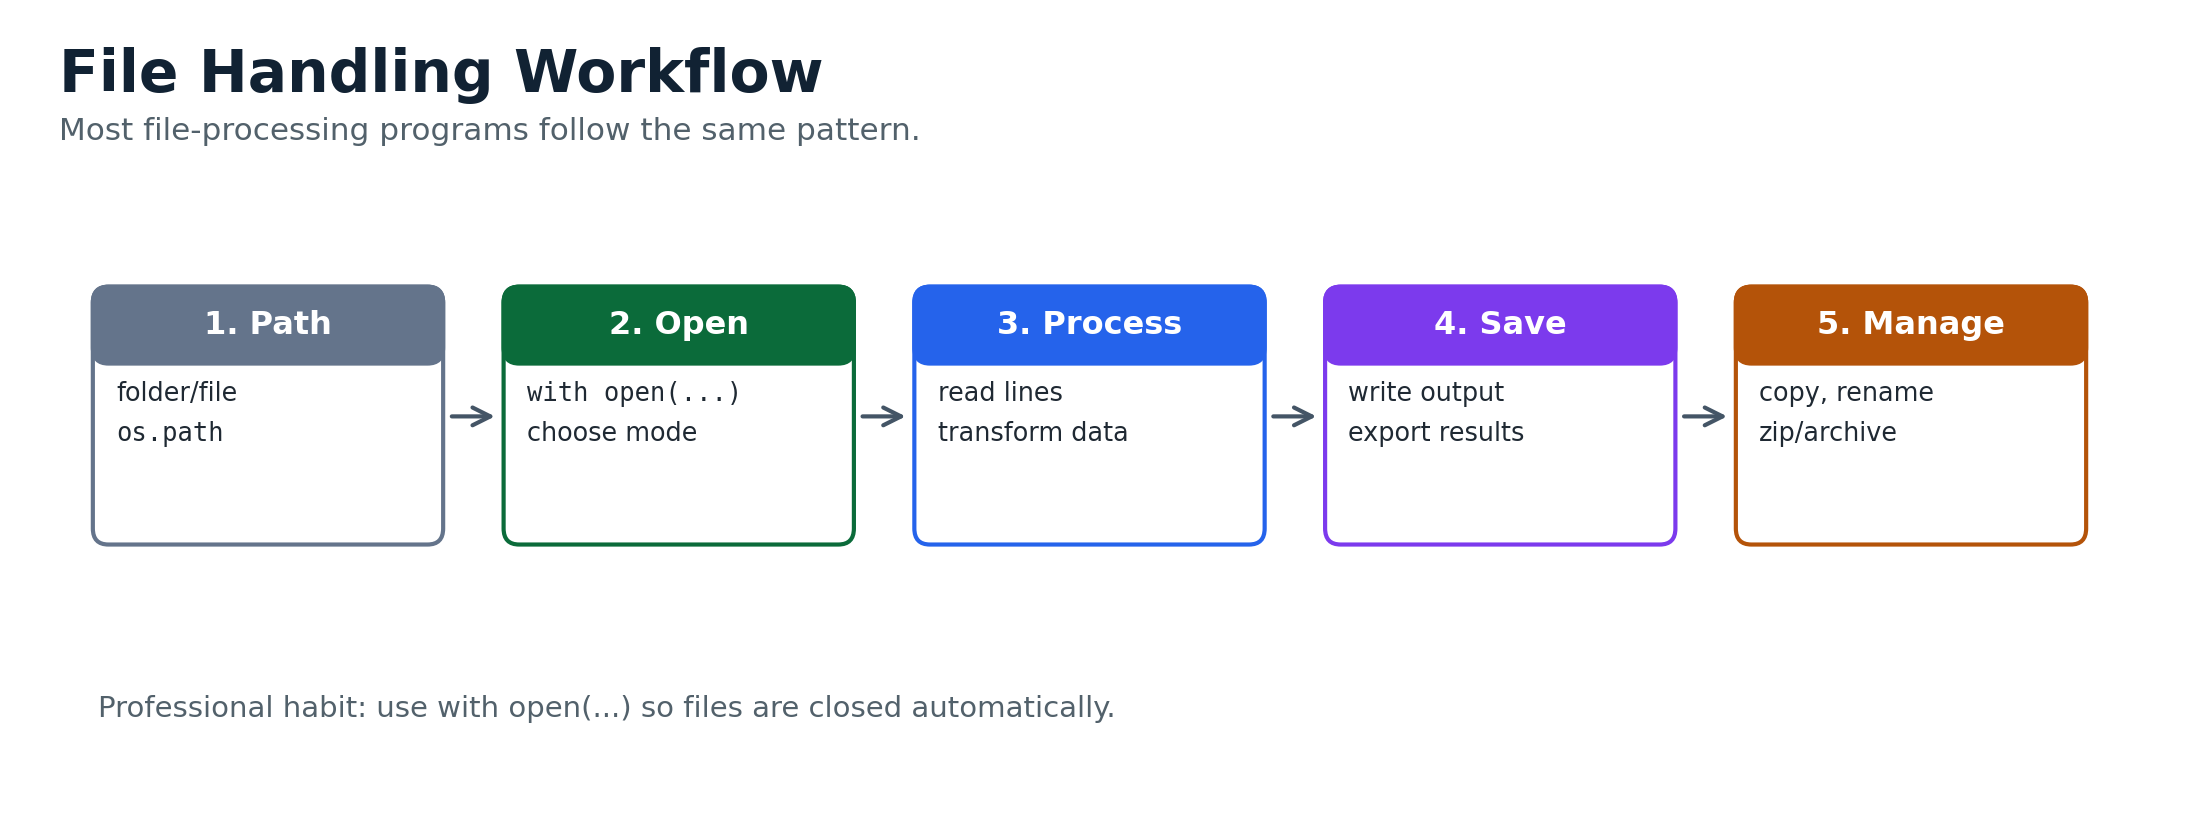<p class="figcap">A common file-handling workflow in Python.</p></div>

# Part 2. Python os Module

The `os` module allows Python to interact with the operating system. It is commonly used to inspect folders, create directories, check whether files exist, and build file paths.

**Assigned reading:** [Python os Module — DataFlair](https://data-flair.training/blogs/python-os-module/)


## More Detail: Why Path Management Matters

A common beginner mistake is writing file paths that only work on one computer. For example, a Windows path may use backslashes, while macOS and Linux often use forward slashes. In cloud notebooks, paths may look different again.

For this reason, students should learn to:

- check the current working directory with `os.getcwd()`;
- list files with `os.listdir()`;
- create folders with `os.makedirs()`;
- check whether a file exists with `os.path.exists()`;
- build portable paths with `os.path.join()`.

These habits make Python code easier to share, debug, and reuse.


<div class="figure">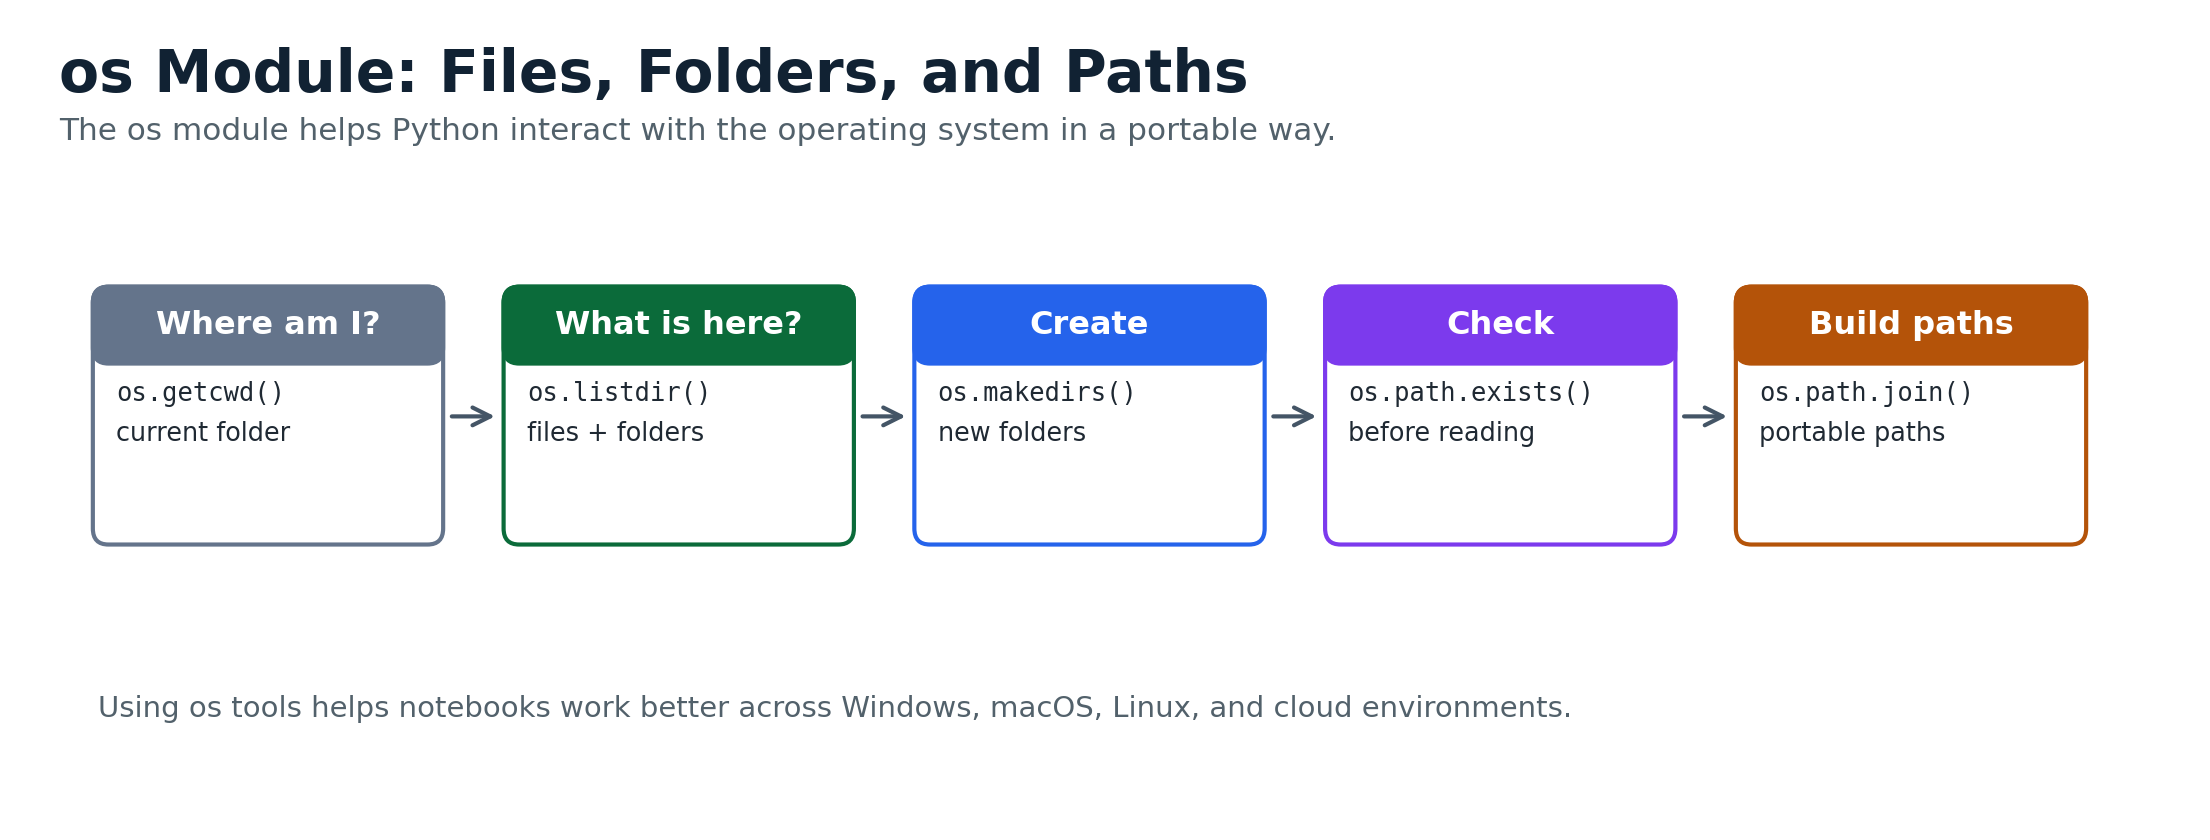<p class="figcap">Common uses of the Python `os` module.</p></div>

In [1]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFirst few files/folders in this directory:")
print(os.listdir(".")[:10])

Current working directory:
/content

First few files/folders in this directory:
['.config', 'sample_data']


## Create a Folder and Build a File Path

Using `os.path.join()` is better than manually typing `/` or `\` because it is more portable across operating systems.


In [2]:
import os

folder = "week10_demo_data"
os.makedirs(folder, exist_ok=True)

file_path = os.path.join(folder, "notes.txt")
print(file_path)

week10_demo_data/notes.txt


## Check Whether a File Exists

Before reading a file, professional code often checks whether the file exists.


In [3]:
if os.path.exists(file_path):
    print("File exists.")
else:
    print("File does not exist yet.")

File does not exist yet.


# Part 3. Python File I/O: Reading and Writing Files

File I/O means input and output operations with files. In Python, the most common approach is to use `with open(...)`.

Key file modes:

| Mode | Meaning | Important note |
|---|---|---|
| `"r"` | Read | File must already exist |
| `"w"` | Write | Overwrites existing content |
| `"a"` | Append | Adds to the end of a file |
| `"x"` | Create | Fails if the file already exists |
| `"rb"` / `"wb"` | Binary read/write | Used for non-text files |

**Assigned readings:**  
- [Python File I/O — DataFlair](https://data-flair.training/blogs/python-file/)  
- [Read and Write File — DataFlair](https://data-flair.training/blogs/file-handling-in-python/)


## More Detail: File Reading Strategies

Different reading methods are useful for different tasks:

| Method | What it does | Best use |
|---|---|---|
| `read()` | Reads the entire file as one string | Small text files |
| `readline()` | Reads one line at a time | Step-by-step reading |
| `readlines()` | Reads all lines into a list | Small-to-medium files |
| `for line in file` | Iterates through lines | Memory-friendly line processing |

For large files, avoid reading everything at once. A line-by-line approach is usually safer.


In [4]:
# Write a text file
with open(file_path, "w", encoding="utf-8") as file:
    file.write("Welcome to Week 10!\n")
    file.write("Today we learn files, exceptions, and testing code.\n")

print("File written:", file_path)

File written: week10_demo_data/notes.txt


In [5]:
# Read the entire file
with open(file_path, "r", encoding="utf-8") as file:
    content = file.read()

print(content)

Welcome to Week 10!
Today we learn files, exceptions, and testing code.



In [6]:
# Read line by line
with open(file_path, "r", encoding="utf-8") as file:
    for line in file:
        print("Line:", line.strip())

Line: Welcome to Week 10!
Line: Today we learn files, exceptions, and testing code.


In [7]:
# Append to the file
with open(file_path, "a", encoding="utf-8") as file:
    file.write("This line was appended later.\n")

with open(file_path, "r", encoding="utf-8") as file:
    print(file.read())

Welcome to Week 10!
Today we learn files, exceptions, and testing code.
This line was appended later.



<div class="warning">
<b>Safety note:</b> Opening a file with <code>"w"</code> overwrites the file. Use <code>"a"</code> when you want to add content to the end of an existing file.
</div>


# Part 4. Copy, Rename, and Zip Files

Python can automate routine file management tasks. This is useful when preparing datasets, backing up files, organizing assignment submissions, or compressing outputs for sharing.

**Assigned materials:**  
- [Zipfile — DataFlair](https://data-flair.training/blogs/python-zipfile/)  
- [Copy a File — DataFlair](https://data-flair.training/blogs/how-python-copy-a-file/)  
- [Rename File — DataFlair](https://data-flair.training/blogs/python-rename-file/)


## More Detail: Safe File Management Checklist

Before copying, renaming, deleting, or overwriting files, check:

1. Does the source file exist?
2. Does the destination file already exist?
3. Am I about to overwrite something important?
4. Should I create a backup first?
5. Is the path correct?

This is especially important when using AI-generated code, because AI may invent file paths or assume file names that do not exist.


<div class="figure">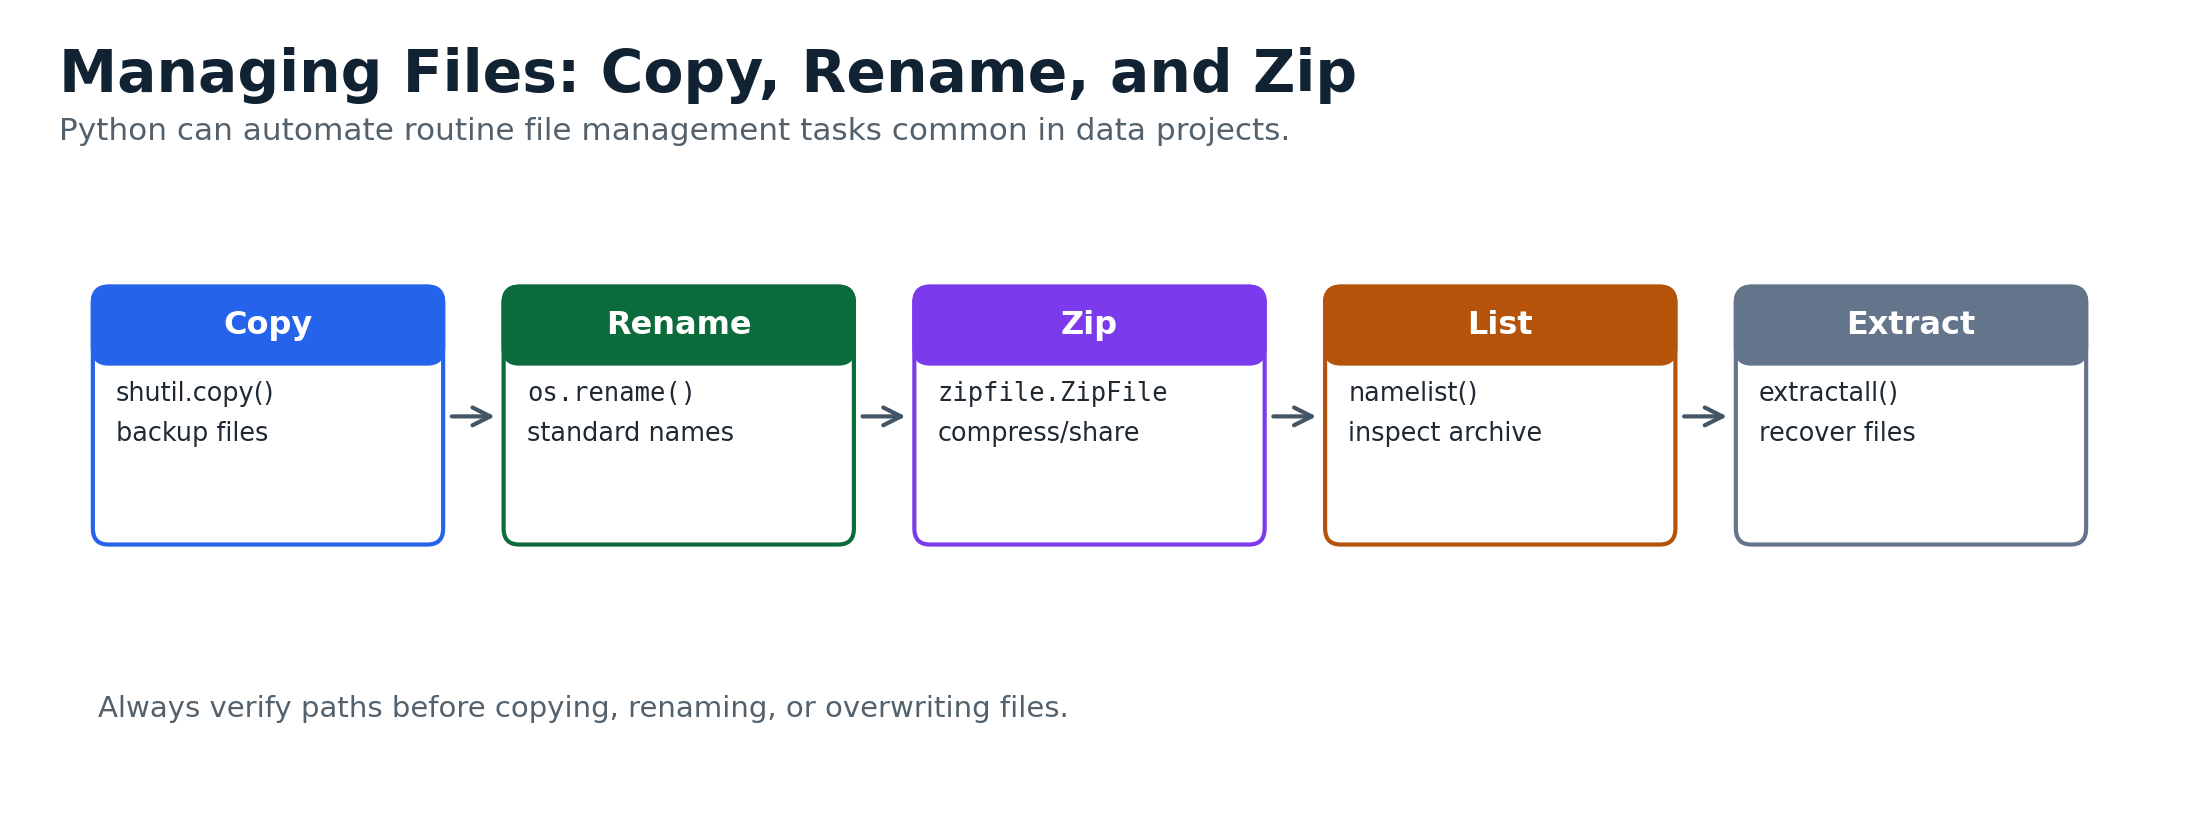<p class="figcap">Common file-management operations in Python.</p></div>

In [8]:
import shutil
import os

source_path = os.path.join("week10_demo_data", "notes.txt")
copy_path = os.path.join("week10_demo_data", "notes_copy.txt")

shutil.copy(source_path, copy_path)
print("Copied to:", copy_path)

Copied to: week10_demo_data/notes_copy.txt


In [9]:
old_path = os.path.join("week10_demo_data", "notes_copy.txt")
new_path = os.path.join("week10_demo_data", "notes_backup.txt")

if os.path.exists(old_path):
    os.rename(old_path, new_path)
    print("Renamed to:", new_path)
else:
    print("File does not exist:", old_path)

Renamed to: week10_demo_data/notes_backup.txt


In [10]:
import zipfile

zip_path = os.path.join("week10_demo_data", "week10_archive.zip")

with zipfile.ZipFile(zip_path, "w") as zip_file:
    zip_file.write(source_path, arcname="notes.txt")

print("Zip file created:", zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_file:
    print("Files in archive:", zip_file.namelist())

Zip file created: week10_demo_data/week10_archive.zip
Files in archive: ['notes.txt']


# Part 5. Exceptions: Handling Expected Problems

An **exception** is a problem detected while a program runs. An unhandled exception stops the current execution. A **syntax error** means Python cannot parse the code, such as when a colon is missing.

Read the last line of an error message first: it usually names the exception and describes the problem. Then use the traceback to find the relevant line of code.

| Exception | Example cause |
|---|---|
| `FileNotFoundError` | Reading a file that does not exist |
| `ValueError` | Converting `"eighty"` to a number |
| `ZeroDivisionError` | Dividing by zero |
| `TypeError` | Adding a string to a number |
| `PermissionError` | Opening a file without the required permission |

Catch the specific exceptions you expect. Avoid an empty `except` block that hides the problem.

**Reference:** [Python tutorial — Errors and Exceptions](https://docs.python.org/3/tutorial/errors.html)

## Example: Read a File with Error Handling

The `try` block contains the operation that may fail. If the file is missing, the matching `except` block gives a useful message and the notebook can continue.

In [11]:
missing_path = os.path.join(folder, "missing_notes.txt")

try:
    with open(missing_path, "r", encoding="utf-8") as file:
        missing_content = file.read()
except FileNotFoundError:
    print("The file was not found. Check the folder and file name:", missing_path)

The file was not found. Check the folder and file name: week10_demo_data/missing_notes.txt


## Example: `try`, `except`, `else`, and `finally`

| Block | When it runs |
|---|---|
| `try` | Attempts an operation |
| `except` | Handles a matching exception raised in `try` |
| `else` | Runs if `try` completes without an exception |
| `finally` | Runs whether or not the operation succeeds; often used for cleanup |

For files, `with open(...)` already handles closing the file. We do not need a `finally` block just to close a file opened with `with`.

In [12]:
for raw_score in ["88", "eighty-eight"]:
    try:
        numeric_score = float(raw_score)
    except ValueError:
        print("Cannot convert this value to a number:", raw_score)
    else:
        print("Converted score:", numeric_score)
    finally:
        print("Finished checking:", raw_score)

Converted score: 88.0
Finished checking: 88
Cannot convert this value to a number: eighty-eight
Finished checking: eighty-eight


## Raise an Exception for Unsuitable Input

The function below expects a nonempty list of numeric scores from 0 to 100. We use `raise ValueError(...)` to explain why an input cannot be processed, rather than allowing an empty list to cause a division-by-zero error.

In [13]:
def calculate_average(scores):
    """Return the mean of a nonempty list of numeric scores from 0 to 100."""
    if not scores:
        raise ValueError("Provide at least one score.")
    if any(score < 0 or score > 100 for score in scores):
        raise ValueError("Scores must be between 0 and 100.")
    return sum(scores) / len(scores)


print("Average:", calculate_average([80, 90, 100]))

try:
    calculate_average([])
except ValueError as error:
    print("Input problem:", error)

Average: 90.0
Input problem: Provide at least one score.


# Part 6. Testing Code

Code can run without an exception and still give the wrong answer. A test compares the **actual result** with an **expected result**.

Choose examples that check different behavior:

| Test category | Input | Expected behavior |
|---|---|---|
| Normal | `[80, 90, 100]` | Average is 90 |
| Single value | `[75]` | Average is 75 |
| Boundaries | `[0, 100]` | Average is 50 |
| Invalid | `[]` or `[105]` | Raise `ValueError` |

For a quick learning check, `assert condition` raises `AssertionError` if the condition is false. Assertions are useful for tests, but do not use them as the only validation of user input: Python can disable assertions when run with optimization.

In [14]:
assert calculate_average([80, 90, 100]) == 90
assert calculate_average([75]) == 75
assert calculate_average([0, 100]) == 50
print("All three quick checks passed.")

All three quick checks passed.


## A Small Automated Test Suite

Python's built-in `unittest` module organizes tests and reports their results. Focus on `assertEqual` for expected results and `assertRaises` for expected exceptions.

We run a named test suite directly so the example works inside a notebook.

**Reference:** [Python documentation — unittest](https://docs.python.org/3/library/unittest.html)

In [15]:
import unittest


class TestCalculateAverage(unittest.TestCase):
    def test_normal_scores(self):
        self.assertEqual(calculate_average([80, 90, 100]), 90)

    def test_single_score(self):
        self.assertEqual(calculate_average([75]), 75)

    def test_boundary_scores(self):
        self.assertEqual(calculate_average([0, 100]), 50)

    def test_empty_scores(self):
        with self.assertRaises(ValueError):
            calculate_average([])

    def test_score_outside_range(self):
        with self.assertRaises(ValueError):
            calculate_average([105])


suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestCalculateAverage)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)

test_boundary_scores (__main__.TestCalculateAverage.test_boundary_scores) ... ok
test_empty_scores (__main__.TestCalculateAverage.test_empty_scores) ... ok
test_normal_scores (__main__.TestCalculateAverage.test_normal_scores) ... ok
test_score_outside_range (__main__.TestCalculateAverage.test_score_outside_range) ... ok
test_single_score (__main__.TestCalculateAverage.test_single_score) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.006s

OK


# Part 7. GenAI-Era Example: Verify File Assumptions

AI-generated code may invent a file path, omit an import, or overwrite a file accidentally. Check the path and file mode before running it, handle expected errors, and test the resulting behavior.

In [16]:
ai_suggested_path = os.path.join("week10_demo_data", "notes.txt")

if os.path.exists(ai_suggested_path):
    print("File exists. Next, read it with appropriate error handling.")
else:
    print("File does not exist. Check the path before reading.")

File exists. Next, read it with appropriate error handling.


# Part 8. In-Class Activities

## Activity 1: Create and Read a File

In [17]:
activity_path = os.path.join("week10_demo_data", "activity.txt")

with open(activity_path, "w", encoding="utf-8") as file:
    file.write("This is my Week 10 activity file.\n")

with open(activity_path, "r", encoding="utf-8") as file:
    print(file.read())

This is my Week 10 activity file.



## Activity 2: Copy and Rename a File


In [18]:
copy_path = os.path.join("week10_demo_data", "activity_copy.txt")
renamed_path = os.path.join("week10_demo_data", "activity_renamed.txt")

shutil.copy(activity_path, copy_path)

if os.path.exists(copy_path):
    os.rename(copy_path, renamed_path)

print("Renamed file exists?", os.path.exists(renamed_path))

Renamed file exists? True


## Activity 3: Handle a Missing File

Write a `try`/`except FileNotFoundError` block to read `student_notes.txt` from the demonstration folder. Display a helpful message if the file is missing. Create the file and run the same code again to check the success case.

## Activity 4: Find a Bug with a Test

Run the intentionally incorrect function below. The test catches the mistake without stopping the notebook. Fix the function so it divides by the number of scores, then rerun the cell.

In [19]:
def average_with_bug(scores):
    return sum(scores) / 2  # Intentional bug: assumes exactly two scores.


try:
    assert average_with_bug([80, 90, 100]) == 90
except AssertionError:
    print("The test found a bug. Check the denominator in average_with_bug().")
else:
    print("The corrected function passed this test.")

The test found a bug. Check the denominator in average_with_bug().


# Part 9. Click-to-Reveal Quiz

Try each question first, then click to reveal the answer.

<div class="quiz">
<p><b>Question 1. Which module helps Python interact with files, folders, and paths?</b></p>

- A. pandas
- B. os
- C. zip
- D. scipy

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. os

<br><br><b>Explanation:</b> The `os` module provides tools for paths, folders, and operating-system interactions.
</details>
</div>

<div class="quiz">
<p><b>Question 2. Why is `with open(...)` recommended?</b></p>

- A. It automatically closes the file
- B. It only works for CSV files
- C. It prevents all errors
- D. It deletes the file

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> A. It automatically closes the file

<br><br><b>Explanation:</b> `with open(...)` manages the file context and closes the file automatically.
</details>
</div>

<div class="quiz">
<p><b>Question 3. Which file mode overwrites an existing file?</b></p>

- A. 'r'
- B. 'a'
- C. 'w'
- D. 'rb'

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> C. 'w'

<br><br><b>Explanation:</b> The `'w'` mode writes to a file and overwrites existing content.
</details>
</div>

<div class="quiz">
<p><b>Question 4. Which module can create and read zip archives?</b></p>

- A. os
- B. shutil
- C. zipfile
- D. pandas

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> C. zipfile

<br><br><b>Explanation:</b> The `zipfile` module is used for working with zip archives.
</details>
</div>

<div class="quiz">
<p><b>Question 5. Which block handles a matching exception raised inside `try`?</b></p>

- A. else
- B. except
- C. finally
- D. assert

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. except

<br><br><b>Explanation:</b> The matching except block handles the expected exception.
</details>
</div>

<div class="quiz">
<p><b>Question 6. What happens when a test uses `assert` with a false condition?</b></p>

- A. Python fixes the function
- B. The file is deleted
- C. AssertionError is raised
- D. The test always passes

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> C. AssertionError is raised

<br><br><b>Explanation:</b> A failed assertion signals that the actual behavior did not meet the test condition.
</details>
</div>

<div class="quiz">
<p><b>Question 7. Which set of tests is most useful for an average-score function?</b></p>

- A. Only one normal input
- B. Normal, boundary, and invalid inputs
- C. Only file names
- D. No expected results

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. Normal, boundary, and invalid inputs

<br><br><b>Explanation:</b> Different input categories help reveal different mistakes.
</details>
</div>

# Part 10. Exit Ticket

Before the next class, answer these questions:

1. What does the `os` module help us do?
2. Why is `with open(...)` recommended?
3. How do `"r"`, `"w"`, and `"a"` differ?
4. When might you copy, rename, or ZIP a file?
5. What exception might occur when reading a missing file?
6. What is the role of `try` and `except`?
7. Why might a function explicitly raise `ValueError`?
8. Why is code that runs without an exception not necessarily correct?
9. Give one normal, one boundary, and one invalid test input for `calculate_average`.

# Week 10 Summary

Today we covered:

- Files, folders, and paths with `os`.
- Reading, writing, and appending text files.
- Copying, renaming, and creating ZIP archives.
- Handling expected exceptions and validating input.
- Testing results with assertions and `unittest`.
- Checking file assumptions in AI-generated code.

## Next Week

**Week 11 | October 26–November 1, 2026**  
**Class date: Monday, October 26, 2026**  
**Lesson 9 — Data Processing and Calculation**

We will use arrays, NumPy, Pandas, and SciPy to calculate, clean, and summarize data.

# Sources and Credits

## File-Handling Readings from the Original Notebook

1. [Python os Module — DataFlair](https://data-flair.training/blogs/python-os-module/)
2. [Python File I/O — DataFlair](https://data-flair.training/blogs/python-file/)
3. [Read and Write File — DataFlair](https://data-flair.training/blogs/file-handling-in-python/)
4. [Zipfile — DataFlair](https://data-flair.training/blogs/python-zipfile/)
5. [Copy a File — DataFlair](https://data-flair.training/blogs/how-python-copy-a-file/)
6. [Rename File — DataFlair](https://data-flair.training/blogs/python-rename-file/)

## Official References

- [Python — os](https://docs.python.org/3/library/os.html)
- [Python — File and Directory Access](https://docs.python.org/3/library/filesys.html)
- [Python — zipfile](https://docs.python.org/3/library/zipfile.html)
- [Python tutorial — Errors and Exceptions](https://docs.python.org/3/tutorial/errors.html)
- [Python — unittest](https://docs.python.org/3/library/unittest.html)

## Credits and Adaptation

File-handling explanations, examples, activities, and embedded diagrams were retained and adapted from the provided previous-term lecture notebook. The exception-handling and testing sections were added to match the current Lesson 8 title. Week labels, dates, demonstration folder names, and review questions were updated for Fall 2026.